# IPCP Lab2 Assignment

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

## bp1)

In [ ]:
def bgr2rgb(img:np.ndarray)->np.ndarray:
  b, g, r = cv.split(img)
  return cv.merge([r, g, b])

Text(0.5, 1.0, 'uw')

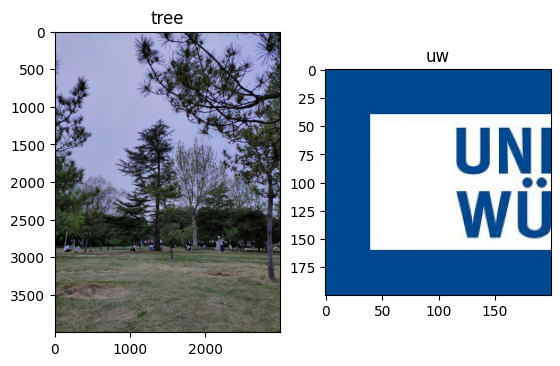

In [ ]:
tree = bgr2rgb(cv.imread("tree.jpg"))
uw = bgr2rgb(cv.imread("uw.jpeg"))
fig, axes = plt.subplots(1, 2)
axes[0].imshow(tree)
axes[0].set_title('tree')
axes[1].imshow(uw)
axes[1].set_title('uw')

In [22]:
if len(tree.shape) == 3:
    tree_gray = cv.cvtColor(tree, cv.COLOR_BGR2GRAY)
    uw_gray = cv.cvtColor(uw, cv.COLOR_BGR2GRAY)
else:
    tree_gray = tree
    uw_gray = uw

## Convolv2d

$$O(x, y) = (I * K)(x, y) = \sum_{m} \sum_{n} I(x - m, y - n) K(m, n)$$

- Cross-Correlation: we need to let the K flip in the 2 directions
- Padding: to keep input size is as same as the output size, so we need pad $p_h = \lfloor k_h / 2 \rfloor$, $p_w = \lfloor k_w / 2 \rfloor$ pixels around the images

- input
  - image: H,W or H,W,C
  - kernel: kh, kw
- output
  - convoluted image: H,W or H,W,C

In [ ]:
def convolve2d(img:np.ndarray, kernel:np.ndarray):
  if kernel.ndim != 2:
    raise ValueError("error: Kernel must be 2d!")
  k_h, k_w = kernel.shape
  kernel_flipped = np.flip(np.flip(kernel, axis=0), axis=1)
  h_pad, w_pad = k_h // 2, k_w // 2
  if img.ndim == 2:
    h, w = img.shape
    padded = np.pad(img, ((h_pad, h_pad), (w_pad, w_pad)), mode='constant', constant_values=0)
    result=np.zeros_like(img, dtype=np.float32)
    for i in range(h):
      for j in range(w):
        win = padded[i:i+k_h, j:j+k_w]
        result[i,j] = np.sum(win * kernel_flipped)
    return result
  elif img.ndim == 3:
    h, w, c= img.shape
    padded = np.pad(img, ((h_pad, h_pad), (w_pad, w_pad), (0, 0)), mode='constant', constant_values=0)
    result=np.zeros_like(img, dtype=np.float32)
    for ch in range(c):
      for i in range(h):
        for j in range(w):
          win = padded[i:i+k_h, j:j+k_w, ch]
          result[i,j,ch] = np.sum(win * kernel_flipped)
    return result

In [ ]:
avg_kernel = 1/9 * np.ones([3, 3])
gau_kernel = 1/16 * np.array([[1,2,1], [2,4,2], [1,2,1]])

Text(0.5, 1.0, 'Gau Filtered UW')

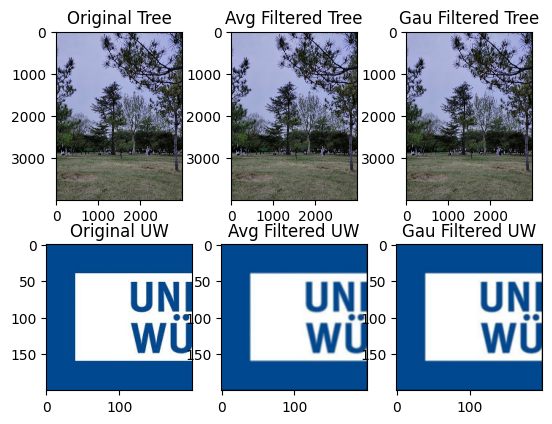

In [ ]:
avg_tree = convolve2d(tree, avg_kernel)
gau_tree = convolve2d(tree, gau_kernel)
avg_uw = convolve2d(uw, avg_kernel)
gau_uw = convolve2d(uw, gau_kernel)
fig, ax = plt.subplots(2, 3)
ax[0, 0].imshow(tree.astype(np.uint8), vmin=0, vmax=255)
ax[0, 0].set_title("Original Tree")
ax[0, 1].imshow(avg_tree.astype(np.uint8), vmin=0, vmax=255)
ax[0, 1].set_title("Avg Filtered Tree")
ax[0, 2].imshow(gau_tree.astype(np.uint8), vmin=0, vmax=255)
ax[0, 2].set_title("Gau Filtered Tree")
ax[1, 0].imshow(uw.astype(np.uint8), vmin=0, vmax=255)
ax[1, 0].set_title("Original UW")
ax[1, 1].imshow(avg_uw.astype(np.uint8), vmin=0, vmax=255)
ax[1, 1].set_title("Avg Filtered UW")
ax[1, 2].imshow(gau_uw.astype(np.uint8), vmin=0, vmax=255)
ax[1, 2].set_title("Gau Filtered UW")

### Gaussian Blur

$$G(x, y) = \frac{1}{2\pi\sigma^2} \exp\left(-\frac{x^2 + y^2}{2\sigma^2}\right)$$

- generate the mesh with base coordinate of (0,0) depends on the size of kernel and standard deviation
- normalization the matrix

In [ ]:
def gaussian_kernel(size:int=5, sigma:float=1.0)->np.ndarray:
    ax = np.linspace(-(size//2), size//2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)

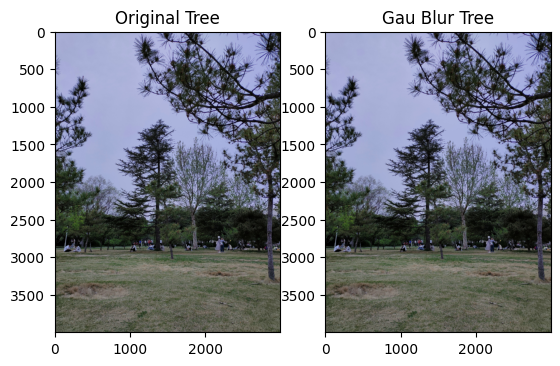

In [ ]:
blurred_tree = convolve2d(tree, gaussian_kernel())
fig, ax = plt.subplots(1, 2)
ax[0].imshow(tree.astype(np.uint8), vmin=0, vmax=255)
ax[0].set_title("Original Tree")
ax[1].imshow(blurred_tree.astype(np.uint8), vmin=0, vmax=255)
ax[1].set_title("Gau Blur Tree")
plt.show()

### Image Gradient

find edges by looking at how fast pixel brightness changes

- N4: Only checks pixels that share an edge (cross shape).
- N8: Checks all pixels that share an edge OR a corner (square shape).

In [ ]:
def gradient_kernels(neighborhood: str = 'N8'):
    if neighborhood == 'N4':
        K_x = np.array([[0, 0, 0],
                        [-1, 0, 1],
                        [0, 0, 0]], dtype=np.float32)

        K_y = np.array([[0, -1, 0],
                        [0,  0, 0],
                        [0,  1, 0]], dtype=np.float32)
    elif neighborhood == 'N8':
        K_x = np.array([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]], dtype=np.float32) / 8.0

        K_y = np.array([[-1, -2, -1],
                        [ 0,  0,  0],
                        [ 1,  2,  1]], dtype=np.float32) / 8.0
    return K_x, K_y

In [ ]:
K_x, K_y = gradient_kernels('N8')
grad_x = convolve2d(tree, K_x)
grad_y = convolve2d(tree, K_y)
grad_magnitude = np.sqrt(grad_x**2 + grad_y**2)

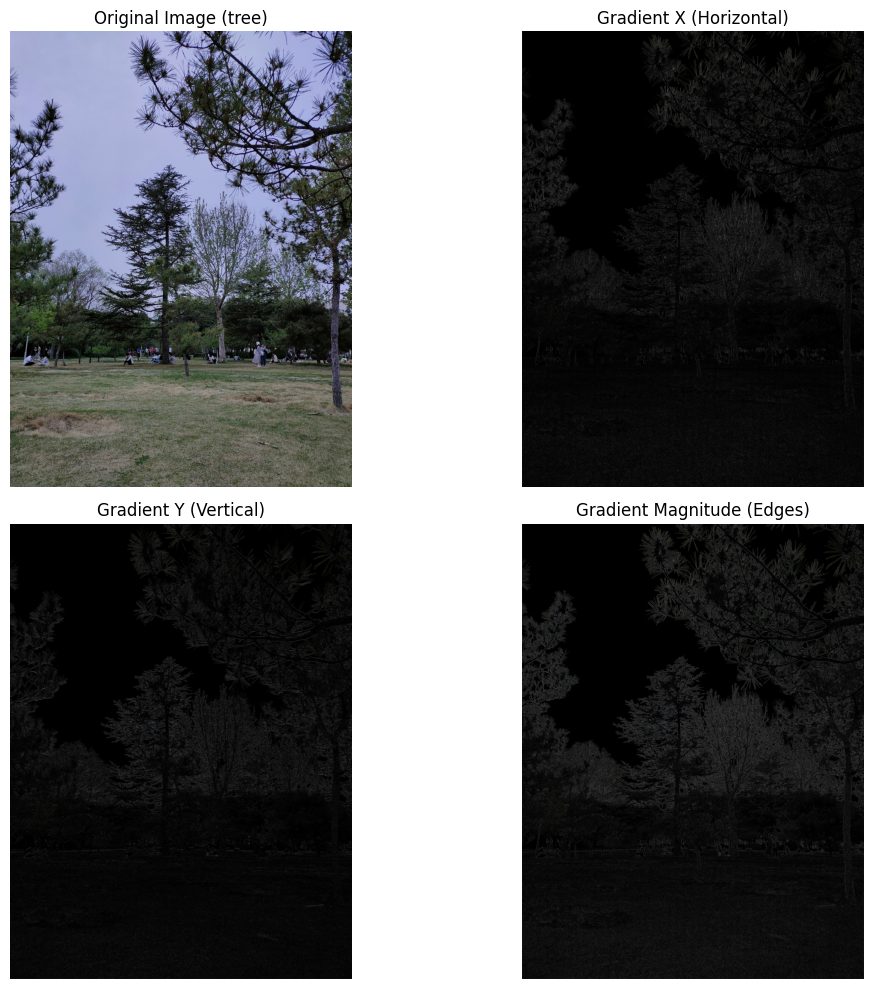

In [23]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(tree.astype(np.uint8), vmin=0, vmax=255, cmap='gray')
plt.title('Original Image (tree)')
plt.axis('off')
# X
plt.subplot(2, 2, 2)
plt.imshow(np.abs(grad_x).astype(np.uint8), vmin=0, vmax=255, cmap='gray')
plt.title('Gradient X (Horizontal)')
plt.axis('off')

# Y
plt.subplot(2, 2, 3)
plt.imshow(np.abs(grad_y).astype(np.uint8), vmin=0, vmax=255, cmap='gray')
plt.title('Gradient Y (Vertical)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(grad_magnitude.astype(np.uint8), vmin=0, vmax=255, cmap='gray')
plt.title('Gradient Magnitude (Edges)')
plt.axis('off')

plt.tight_layout()
plt.show()


### Laplacian Edge Detection

$$\nabla^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2}$$

- Zero-crossing when edges exist
- define a kernel with minus core and other element >0, and also the shape is 3*3 with all elements adding equals 0

In [ ]:
def laplacian_kernel() -> np.ndarray:
    return np.array([[0,  1, 0],
                     [1, -4, 1],
                     [0,  1, 0]], dtype=np.float32)

lap_kernel = laplacian_kernel()
edge_tree = convolve2d(tree, lap_kernel)

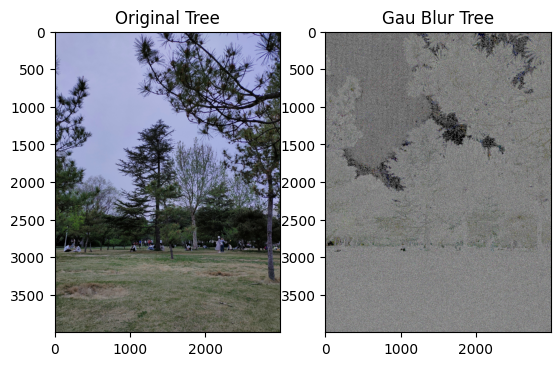

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].imshow(tree.astype(np.uint8), vmin=0, vmax=255)
ax[0].set_title("Original Tree")
ax[1].imshow(edge_tree.astype(np.uint8), vmin=0, vmax=255)
ax[1].set_title("Gau Blur Tree")
plt.show()

### Harris Corner Detection

base on the structure tensor:
$$M = \sum_{w} \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix} = \begin{bmatrix} S_{xx} & S_{xy} \\ S_{xy} & S_{yy} \end{bmatrix}$$
$I_x, I_y$ is image gradient, $w$ is gaussian weighted window
Corner value is $$R = \det(M) - k \cdot (\text{trace}(M))^2 = (S_{xx} S_{yy} - S_{xy}^2) - k \cdot (S_{xx} + S_{yy})^2$$
when R>0 and the value is relativly big, shows the eigenvalues from both directions are big, so it is corner

In [ ]:
def harris_corner_response(gray_img: np.ndarray, k: float = 0.04, sigma: float = 1.0) -> np.ndarray:
    K_x, K_y = gradient_kernels('N8')
    Ix = convolve2d(gray_img, K_x)
    Iy = convolve2d(gray_img, K_y)

    Ixx = Ix ** 2
    Iyy = Iy ** 2
    Ixy = Ix * Iy

    w_kernel = gaussian_kernel(size=5, sigma=sigma)
    Sxx = convolve2d(Ixx, w_kernel)
    Syy = convolve2d(Iyy, w_kernel)
    Sxy = convolve2d(Ixy, w_kernel)

    det_M = (Sxx * Syy) - (Sxy ** 2)
    trace_M = Sxx + Syy
    R = det_M - k * (trace_M ** 2)
    return R


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


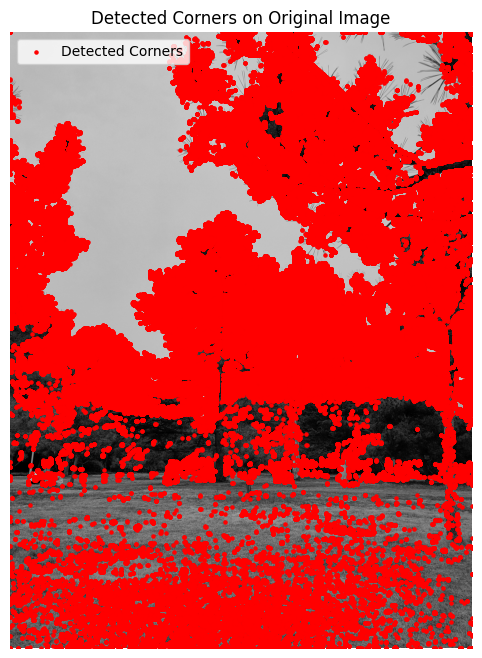

In [25]:
harris_response_map = harris_corner_response(tree_gray)

threshold = 0.01 * harris_response_map.max()
corners = harris_response_map > threshold

y_coords, x_coords = np.where(corners)

plt.figure(figsize=(10, 8))
plt.imshow(tree_gray, cmap='gray')
plt.scatter(x_coords, y_coords, color='red', s=5, marker='o', label='Detected Corners')
plt.title('Detected Corners on Original Image')
plt.axis('off')
plt.legend()
plt.show()


### LoG - Laplacian Gaussian

$$\text{LoG}(x, y) = -\frac{1}{\pi \sigma^4} \left(1 - \frac{x^2 + y^2}{2\sigma^2}\right) \exp\left(-\frac{x^2 + y^2}{2\sigma^2}\right)$$

the Laplacian of Gaussian (LoG) kernel ensures its values sum to zero, giving a flat background zero response so constant areas produce no output.

In [ ]:
def get_log_kernel(size: int = 9, sigma: float = 1.4) -> np.ndarray:
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    norm_sq = xx**2 + yy**2

    kernel = -1.0 / (np.pi * sigma**4) * (1.0 - norm_sq / (2.0 * sigma**2)) * np.exp(-norm_sq / (2.0 * sigma**2))
    return kernel - np.mean(kernel)


log_k = get_log_kernel(size=9, sigma=1.4)
log_blob_img = convolve2d(tree, log_k)


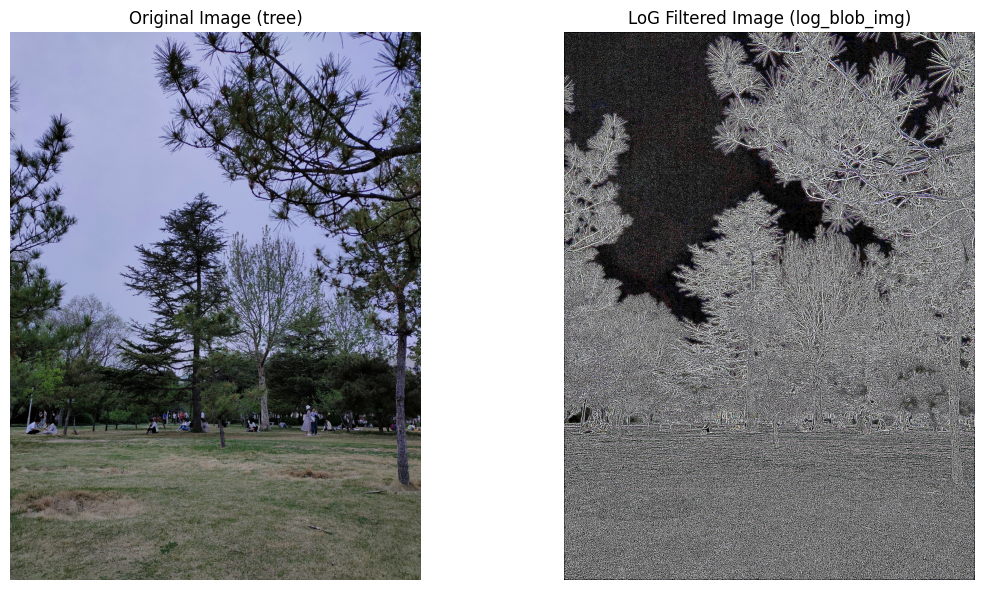

In [26]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Original Image (tree)")
plt.imshow(tree, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("LoG Filtered Image (log_blob_img)")
plt.imshow(log_blob_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### Gabor Filter Bank

$$g(x, y; \lambda, \theta, \psi, \sigma, \gamma) = \exp\left(-\frac{x'^2 + \gamma^2 y'^2}{2\sigma^2}\right) \cos\left(2\pi \frac{x'}{\lambda} + \psi\right)$$
$$x' = x \cos\theta + y \sin\theta, \quad y' = -x \sin\theta + y \cos\theta$$

$\theta$:Orientation

$\lambda$:Scale

$\gamma$:Aspect ratio

$\psi$:Phase offset

- generate gabor kernel based on the defination
- get a set of diverse angle(0, 45, 90, 135) and different λ

In [ ]:
def get_gabor_kernel(size: int = 15, sigma: float = 3.0, theta: float = 0.0,
                     lambd: float = 6.0, gamma: float = 0.5, psi: float = 0.0) -> np.ndarray:
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)

    x_theta = xx * np.cos(theta) + yy * np.sin(theta)
    y_theta = -xx * np.sin(theta) + yy * np.cos(theta)

    gb = np.exp(-0.5 * (x_theta**2 + (gamma * y_theta)**2) / sigma**2) * np.cos(2 * np.pi * x_theta / lambd + psi)
    return gb

def create_gabor_bank(num_orientations: int = 4, lambdas: list = [4, 8]) -> list:
    bank = []
    for lambd in lambdas:
        for i in range(num_orientations):
            theta = i * np.pi / num_orientations
            kernel = get_gabor_kernel(size=15, sigma=3.0, theta=theta, lambd=lambd)
            bank.append(kernel)
    return bank

gabor_bank = create_gabor_bank(num_orientations=4, lambdas=[6.0])
gabor_features = [convolve2d(tree, k) for k in gabor_bank]


## **1bp** 2

### Histogram Matching

- reflects the frequency of occurrence of pixels with different grayscale levels or color values ​​in an image, and can be considered a first-order statistic of the image's color and brightness distribution.

- PDF: $P(g) = \frac{n_g}{N}$
- CDF:$$S(g) = \sum_{i=0}^{g} P(i)$$

- caculate PDF and CDF
- find the minimum grayscale levels in CDF
- iterate through the source image and map each pixel using the pre-constructed lookup table $M$.

In [27]:
import numpy as np

def match_histogram_channel(source_channel: np.ndarray, reference_channel: np.ndarray) -> np.ndarray:
    src_hist, _ = np.histogram(source_channel.ravel(), bins=256, range=(0, 256), density=True)
    ref_hist, _ = np.histogram(reference_channel.ravel(), bins=256, range=(0, 256), density=True)

    src_cdf = np.cumsum(src_hist)
    ref_cdf = np.cumsum(ref_hist)

    src_cdf = src_cdf / src_cdf[-1]
    ref_cdf = ref_cdf / ref_cdf[-1]

    lut = np.zeros(256, dtype=np.uint8)
    for i in range(256):
        diff = np.abs(ref_cdf - src_cdf[i])
        lut[i] = np.argmin(diff)

    return lut[source_channel]

def histogram_matching(input_img: np.ndarray, ref_img: np.ndarray) -> np.ndarray:

    if input_img.ndim == 2:
        return match_histogram_channel(input_img, ref_img)
    elif input_img.ndim == 3:
        matched_channels = [
            match_histogram_channel(input_img[:, :, c], ref_img[:, :, c])
            for c in range(input_img.shape[2])
        ]
        return np.stack(matched_channels, axis=-1)
    else:
        raise ValueError("Unsupported image dimensions.")

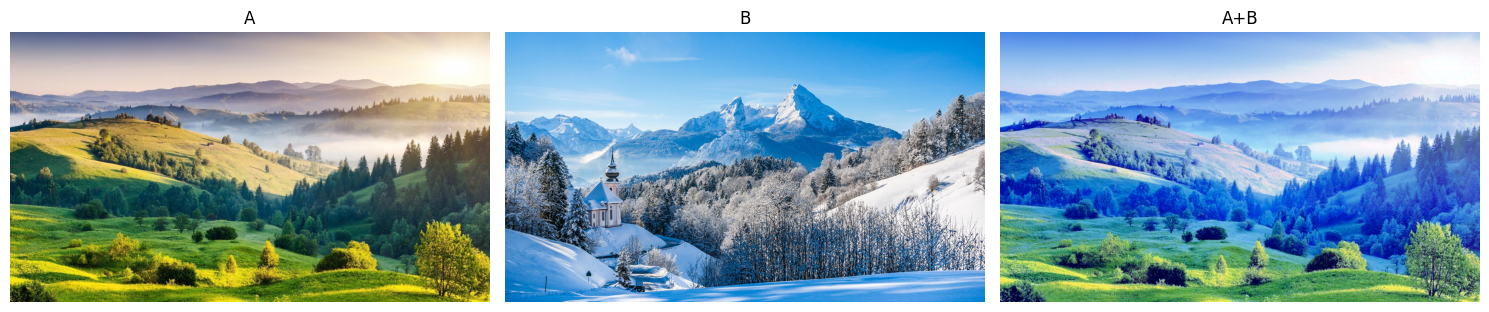

In [28]:
src_bgr = cv.imread('a.jpg')
ref_bgr = cv.imread('b.jpg')

src_rgb = cv.cvtColor(src_bgr, cv.COLOR_BGR2RGB)
ref_rgb = cv.cvtColor(ref_bgr, cv.COLOR_BGR2RGB)

res_rgb = histogram_matching(src_rgb, ref_rgb)

res_bgr = cv.cvtColor(res_rgb, cv.COLOR_RGB2BGR)
cv.imwrite('result_a_to_b.png', res_bgr)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(src_rgb)
axes[0].set_title("A")
axes[0].axis('off')

axes[1].imshow(ref_rgb)
axes[1].set_title("B")
axes[1].axis('off')

axes[2].imshow(res_rgb)
axes[2].set_title("A+B")
axes[2].axis('off')

plt.tight_layout()
plt.show()


## bp3)

### 1. Image Denoising
Input - Reference Pair: An underexposed night photo shot at high ISO (ISO 12400) vs. A clean reference captured at base ISO (ISO 100) on a sturdy tripod with longer exposure.

Histogram Difference: Noise adds high-frequency random variations (Gaussian/Poisson noise), smoothing out sharp peaks and broadening the histogram bins. The reference histogram exhibits smoother, well-defined peaks without high-frequency noise ripples.

Contrast Change: Noise elevates the noise floor in dark regions, reducing local spatial contrast and obscuring fine details in shadow areas.

Photographer Solutions & Gear: Lower camera ISO, utilize a tripod, select a wider aperture (
f/1.4 or
f/2.8)

### 2. Image Deblurring
Input - Reference Pair: A motion-blurred or out-of-focus photo vs. A crisp, properly focused photo taken with a fast shutter speed.

Histogram Difference: Blur acts as a convolution with a Point Spread Function, pulling extreme intensity values toward the global mean, causing the histogram to narrow. The reference histogram shows wider distribution with sharper peaks at bright and dark boundaries.

Contrast Change: High-frequency spatial edge contrast is severely degraded, eliminating sharp boundaries and fine structural contrast.

Photographer Solutions & Gear: Increase shutter speed, enable Optical/In-Body Image Stabilization (OIS), use a fast prime lens, align autofocus/focus peaking, and use a tripod for a stable capture.


### 3. Image Super-Resolution
Input - Reference Pair: A low-resolution downsampled/cropped image vs. A native high-resolution RAW image captured with a high-megapixel camera sensor.

Histogram Difference: The overall normalized histogram profile remains similar, but the low-resolution image histogram lacks finer intensity quantization steps and sub-pixel granularity once interpolated.

Contrast Change: Fine texture contrast and micro-edge sharpness are lost in the low-resolution image.

Photographer Solutions & Gear: Upgrade to a high-resolution camera sensor, move closer to the subject instead of cropping digitally.


### 4. Image Dehazing
Input - Reference Pair: A hazy landscape photo impacted by atmospheric light scattering vs. A clear landscape photo captured after rain.

Histogram Difference: The hazy image histogram is compressed into a narrow range of mid-to-high brightness values due to atmospheric airlight, lacking true black levels. The reference image histogram spans the full dynamic range (
0 to
255).

Contrast Change: Significant loss of global contrast, dynamic range, and chromatic saturation.

Photographer Solutions & Gear: use a lens hood, shoot at high altitudes or on clear days, and shoot during early morning/late afternoon when air path scattering is lower.

### 5. Low-light Image Enhancement
Input - Reference Pair: An underexposed photo taken in dark indoor conditions vs. A well-exposed photo shot with artificial fill lighting/flash.

Histogram Difference: The low-light histogram is severely skewed to the left (heavily populated in the range
0-50). The reference histogram displays a balanced distribution across shadow, midtone, and highlight regions.

Contrast Change: Low tonal contrast in dark regions; clipping occurs at the lower intensity threshold (
0), causing shadow detail compression.

Photographer Solutions & Gear: adjust exposure compensation, increase exposure time, open aperture, or use reflectors.


### 6. Ambient Color Normalization
Input - Reference Pair: A photo with a heavy warm color cast taken under tungsten light vs. A neutral daylight-balanced photo calibrated with a gray card.

Histogram Difference: Per-channel (RGB) histograms are significantly misaligned in the color-casted image. The normalized reference image exhibits overlapping, well-balanced RGB channel histograms.

Contrast Change: Inter-channel color contrast is unbalanced, degrading true chrominance contrast and color accuracy.

Photographer Solutions & Gear: set camera Kelvin temperature manually, and capture images in uncompressed RAW format for non-destructive white balance adjustment.